In [113]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.base import TransformerMixin, BaseEstimator
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score, confusion_matrix
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split, cross_val_score
 

### EDA

In [114]:
df = sns.load_dataset('titanic')
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [115]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    str     
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    str     
 8   class        891 non-null    category
 9   who          891 non-null    str     
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    str     
 13  alive        891 non-null    str     
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), str(5)
memory usage: 80.7 KB


In [116]:
df.describe()

,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [117]:
df[df['fare'] == 0]#.shape

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
179,0,3,male,36.0,0,0,0.0,S,Third,man,True,NaN,Southampton,no,True
263,0,1,male,40.0,0,0,0.0,S,First,man,True,B,Southampton,no,True
271,1,3,male,25.0,0,0,0.0,S,Third,man,True,NaN,Southampton,yes,True
277,0,2,male,NaN,0,0,0.0,S,Second,man,True,NaN,Southampton,no,True
302,0,3,male,19.0,0,0,0.0,S,Third,man,True,NaN,Southampton,no,True
413,0,2,male,NaN,0,0,0.0,S,Second,man,True,NaN,Southampton,no,True
466,0,2,male,NaN,0,0,0.0,S,Second,man,True,NaN,Southampton,no,True
481,0,2,male,NaN,0,0,0.0,S,Second,man,True,NaN,Southampton,no,True
597,0,3,male,49.0,0,0,0.0,S,Third,man,True,NaN,Southampton,no,True
633,0,1,male,NaN,0,0,0.0,S,First,man,True,NaN,Southampton,no,True


In [118]:
df['alive'].value_counts()

alive
no     549
yes    342
Name: count, dtype: int64

In [119]:
df['survived'].value_counts()

survived
0    549
1    342
Name: count, dtype: int64

In [120]:
((df['alive'] == 'yes') == df['survived']).sum()

np.int64(891)

In [121]:
df['embark_town'].value_counts()

embark_town
Southampton    644
Cherbourg      168
Queenstown      77
Name: count, dtype: int64

In [122]:
df['embarked'].value_counts()

embarked
S    644
C    168
Q     77
Name: count, dtype: int64

In [123]:
(df['embark_town'].map({'Southampton': 'S', 'Cherbourg': 'C', 'Queenstown': 'Q'}) == df['embarked']).sum()

np.int64(889)

In [124]:
(df['pclass'].map({1: 'First', 2: 'Second', 3: 'Third'}) == df['class']).sum()

np.int64(891)

In [125]:
df.groupby(['sex', 'adult_male', 'who']).agg({
    'age': 'mean',
    'survived': 'mean'
}).round(2)

age  survived
sex    adult_male who                   
female False      child   7.21      0.65
                  woman  32.00      0.76
male   False      child   5.47      0.52
       True       man    33.17      0.16

In [126]:
df[df['age'].isna()].groupby('who')[['survived']].count()

,survived
who,
man,124
woman,53


In [127]:
df['age'].median().round(), df[df['who'] != 'child']['age'].median().round()

(np.float64(28.0), np.float64(30.0))

In [128]:
df.groupby('class')['survived'].mean().round(2)

class
First     0.63
Second    0.47
Third     0.24
Name: survived, dtype: float64

In [129]:
df[(df['parch'] == 0) & (df['sibsp'] == 0)]['alone'].value_counts()

alone
True    537
Name: count, dtype: int64

In [130]:
def survived_vc(col):
    return col.value_counts().to_dict()
df.groupby(['alone', 'who'])['survived'].agg(['count', 'mean', survived_vc])

count      mean      survived_vc
alone who                                    
False child     77  0.584416   {1: 45, 0: 32}
      man      127  0.188976  {0: 103, 1: 24}
      woman    150  0.733333  {1: 110, 0: 40}
True  child      6  0.666667     {1: 4, 0: 2}
      man      410  0.156098  {0: 346, 1: 64}
      woman    121  0.785124   {1: 95, 0: 26}

### Data Cleaning

### Feature Engineering

In [131]:
df_tmp = pd.DataFrame({
    'a': [1, 2, 3, np.nan],
    'b': ['a', 'a', 'b', np.nan]
})
imputer = ColumnTransformer(
    [('num', SimpleImputer(strategy='median'), ['a']),
    ('cat', SimpleImputer(strategy='most_frequent'), ['b'])])
imputer.fit_transform(df_tmp)

array([[1.0, 'a'],
       [2.0, 'a'],
       [3.0, 'b'],
       [2.0, 'a']], dtype=object)

In [132]:
df['age']

0      22.0
1      38.0
2      26.0
3      35.0
4      35.0
       ... 
886    27.0
887    19.0
888     NaN
889    26.0
890    32.0
Name: age, Length: 891, dtype: float64

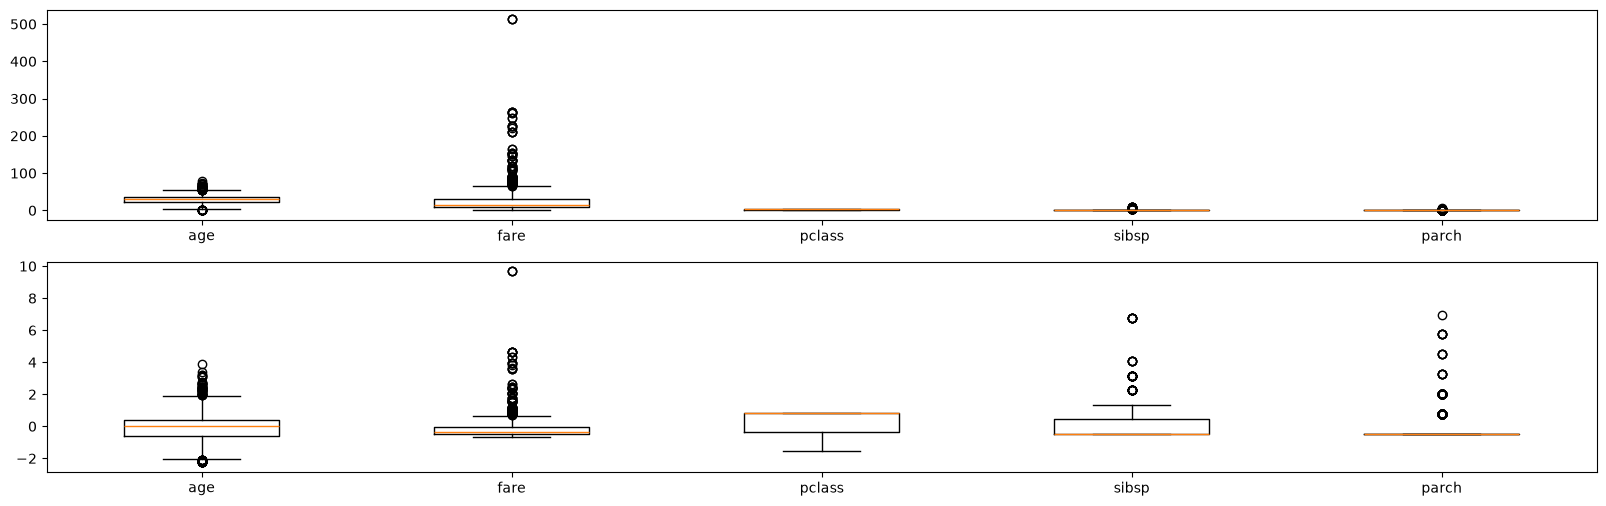

In [133]:
fig, ax = plt.subplots(2, 1, figsize=(20, 6))
num_cols = ['age', 'fare', 'pclass', 'sibsp', 'parch']
df_tmp = df[num_cols].copy()
df_tmp.loc[df['age'].isna(), 'age'] = df['age'].mean()
df_tmp_scaled = pd.DataFrame(StandardScaler().fit_transform(df_tmp), columns=num_cols)
ax[0].boxplot(df_tmp)
ax[0].set_xticks(range(1, len(num_cols) + 1), num_cols)
ax[1].boxplot(df_tmp_scaled)
ax[1].set_xticks(range(1, len(num_cols) + 1), num_cols);

In [134]:
sr_is_child = df['who'] == 'child'
sr_is_male = df['sex'] == 'male'
df[['who', 'sex', 'adult_male']].assign(is_child=sr_is_child, is_male=sr_is_male)

,who,sex,adult_male,is_child,is_male
0,man,male,True,False,True
1,woman,female,False,False,False
2,woman,female,False,False,False
3,woman,female,False,False,False
4,man,male,True,False,True
...,...,...,...,...,...
886,man,male,True,False,True
887,woman,female,False,False,False
888,woman,female,False,False,False
889,man,male,True,False,True


In [135]:
(
    OneHotEncoder(sparse_output=False, handle_unknown='ignore', drop='first')
    .set_output(transform='pandas')
    .fit_transform(df[['sex', 'who']])
    .join(df[['sex', 'who']])
    .loc[10:20]
)

,sex_male,who_man,who_woman,sex,who
10,0.0,0.0,0.0,female,child
11,0.0,0.0,1.0,female,woman
12,1.0,1.0,0.0,male,man
13,1.0,1.0,0.0,male,man
14,0.0,0.0,0.0,female,child
15,0.0,0.0,1.0,female,woman
16,1.0,0.0,0.0,male,child
17,1.0,1.0,0.0,male,man
18,0.0,0.0,1.0,female,woman
19,0.0,0.0,1.0,female,woman


In [136]:
# FunctionTransformer
# def is_child(x):
#     return x == 'child'
# child = FunctionTransformer(is_child)
child = FunctionTransformer(lambda x: (x == 'child'))
child.fit_transform(df[['who']])

,who
0,False
1,False
2,False
3,False
4,False
...,...
886,False
887,False
888,False
889,False


In [137]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    str     
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    str     
 8   class        891 non-null    category
 9   who          891 non-null    str     
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    str     
 13  alive        891 non-null    str     
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), str(5)
memory usage: 80.7 KB


In [138]:
age_proc = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])
embarked_proc = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False))
])
     
child_proc = FunctionTransformer(lambda x: (x == 'child'))

feature_eng1 = ColumnTransformer([
    ('age', age_proc, ['age']),
    ('num_scale', StandardScaler(), ['fare', 'parch', 'sibsp', 'pclass']),
    ('is_child', child_proc, ['who']),
    ('sex', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False), ['sex']),
    ('embarked', embarked_proc, ['embarked']),
    ('alone', 'passthrough', ['alone']),
])
feature_eng1.set_output(transform='pandas').fit_transform(df)

,age__age,num_scale__fare,num_scale__parch,num_scale__sibsp,num_scale__pclass,is_child__who,sex__sex_male,embarked__embarked_Q,embarked__embarked_S,alone__alone
0,-0.565736,-0.502445,-0.473674,0.432793,0.827377,False,1.0,0.0,1.0,False
1,0.663861,0.786845,-0.473674,0.432793,-1.566107,False,0.0,0.0,0.0,False
2,-0.258337,-0.488854,-0.473674,-0.474545,0.827377,False,0.0,0.0,1.0,True
3,0.433312,0.420730,-0.473674,0.432793,-1.566107,False,0.0,0.0,1.0,False
4,0.433312,-0.486337,-0.473674,-0.474545,0.827377,False,1.0,0.0,1.0,True
...,...,...,...,...,...,...,...,...,...,...
886,-0.181487,-0.386671,-0.473674,-0.474545,-0.369365,False,1.0,0.0,1.0,True
887,-0.796286,-0.044381,-0.473674,-0.474545,-1.566107,False,0.0,0.0,1.0,True
888,-0.104637,-0.176263,2.008933,0.432793,0.827377,False,0.0,0.0,1.0,False
889,-0.258337,-0.044381,-0.473674,-0.474545,-1.566107,False,1.0,0.0,0.0,True


In [139]:
feature_eng1

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('age', ...), ('num_scale', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``fea

In [140]:
def fam_size(df):
    return pd.DataFrame({'family_size': df['sibsp'] + df['parch'] + 1}, index=df.index)

fam_proc = Pipeline([
    ('fam_size', FunctionTransformer(
        fam_size, feature_names_out=lambda inp, outp: ['family_size'])),
    ('scaler', StandardScaler())
])
feature_eng2 = ColumnTransformer([
    ('age', age_proc, ['age']),
    ('family_size', fam_proc, ['sibsp', 'parch']),
    ('num_scale', StandardScaler(), ['fare', 'pclass', 'sibsp', 'parch']),
    ('is_child', child_proc, ['who']),
    ('sex', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False), ['sex']),
    ('embarked', embarked_proc, ['embarked']),
    ('alone', 'passthrough', ['alone']),
])
feature_eng2.set_output(transform='pandas').fit_transform(df).head(2)

,age__age,family_size__family_size,num_scale__fare,num_scale__pclass,num_scale__sibsp,num_scale__parch,is_child__who,sex__sex_male,embarked__embarked_Q,embarked__embarked_S,alone__alone
0,-0.565736,0.05916,-0.502445,0.827377,0.432793,-0.473674,False,1.0,0.0,1.0,False
1,0.663861,0.05916,0.786845,-1.566107,0.432793,-0.473674,False,0.0,0.0,0.0,False


In [141]:
feature_eng2

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('age', ...), ('family_size', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``f

In [142]:
X = df.drop(columns=['survived', 'alive'])
y = df['survived']

### Model Training

In [143]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"Training set size: {X_train.shape}")

Training set size: (712, 13)


In [144]:
model = Pipeline([
    ('features', feature_eng1),
    ('classifier', LogisticRegression())
])
model.fit(X_train, y_train)
y_pred1 = model.predict(X_test)

In [145]:
model = Pipeline([
    ('features', feature_eng2),
    ('classifier', LogisticRegression())
])
model.fit(X_train, y_train)
y_pred2 = model.predict(X_test)

### Evalualuation

**Classification Metrics**
$$
\text{Precision} = \frac{\text{True Positives}}{\text{True Positives} + \text{False Positives}}
$$
$$
\text{Recall} = \frac{\text{True Positives}}{\text{True Positives} + \text{False Negatives}}
$$
$$
\text{Accuracy} = \frac{\text{True Positives} + \text{True Negatives}}{\text{TP} + \text{FN} + \text{FP} + \text{TN}}
$$

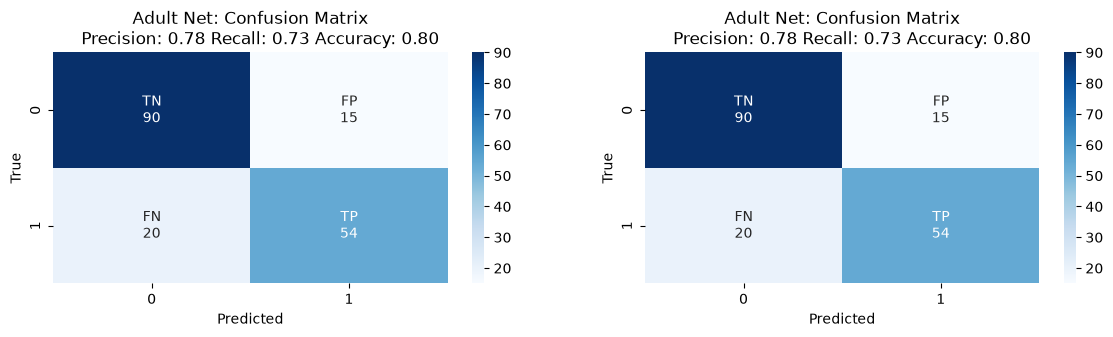

In [146]:
def plot_confusion_matrix(y_true, y_pred, ax, label):
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    annotations = np.array([[f'TN\n{cm[0, 0]}', f'FP\n{cm[0, 1]}'],
                            [f'FN\n{cm[1, 0]}', f'TP\n{cm[1, 1]}']])
    sns.heatmap(cm, annot=annotations, fmt='', cmap='Blues', ax=ax)
    precision_large, recall_large, accuracy_large = precision_score(y_true, y_pred), recall_score(y_true, y_pred), accuracy_score(y_true, y_pred)
    ax.set_title(f"""{label} Net: Confusion Matrix
    Precision: {precision_large:.2f} Recall: {recall_large:.2f} Accuracy: {accuracy_large:.2f}""")
    ax.set_xlabel('Predicted')
    ax.set_ylabel('True')

fig, ax = plt.subplots(1, 2, figsize=(14, 3))
plot_confusion_matrix(y_test, y_pred1, ax[0], "Adult")
plot_confusion_matrix(y_test, y_pred2, ax[1], "Adult")

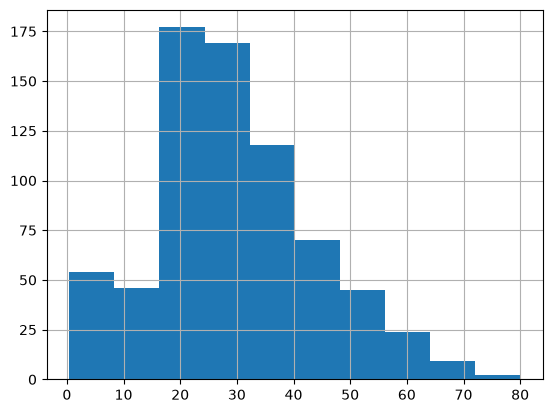

<Axes: >

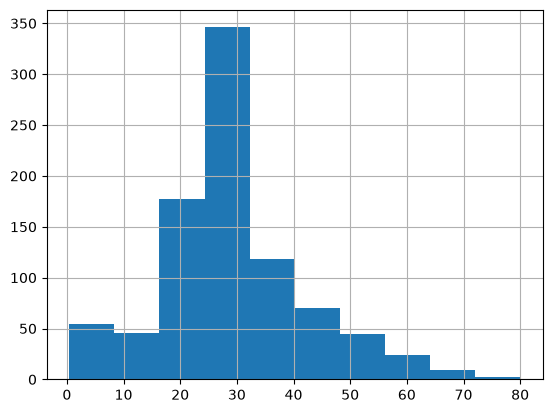

In [147]:
class AgeGroupImputer(TransformerMixin):
    def __init__(self, strategy='median', col='who'):
        self.strategy = strategy
        self.col = col
 
    def fit(self, X, y=None):
        self.age_groups_ = X.groupby(self.col)['age'].agg(self.strategy)
        return self
 
    def transform(self, X, y=None):
        X = X.copy()
        for row in self.age_groups_.index:
            X.loc[(X[self.col] == row) & X['age'].isna(), 'age'] = self.age_groups_[row]
        return X
 
agi = AgeGroupImputer()
df['age'].hist()
plt.show()
agi.fit_transform(df)['age'].hist()
 

In [148]:
def fam_size(df):
    return pd.DataFrame({'family_size': df['sibsp'] + df['parch'] + 1}, index=df.index)
 
fam_proc = Pipeline([
    ('fam_size', FunctionTransformer(
        fam_size, feature_names_out=lambda inp, outp: ['family_size'])),
    ('scaler', StandardScaler())
])      
age_proc_smart_imp = Pipeline([
    ('age_imputer', AgeGroupImputer()),
    ('age_scaler', StandardScaler())
])
 
feature_eng2 = ColumnTransformer([
    ('age', age_proc_smart_imp, ['age', 'who']),
    ('family_size', fam_proc, ['sibsp', 'parch']),
    ('num_scale', StandardScaler(), ['fare', 'pclass', 'sibsp', 'parch']),
    ('is_child', child_proc, ['who']),
    ('sex', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False), ['sex']),
    ('embarked', embarked_proc, ['embarked']),
    ('alone', 'passthrough', ['alone']),
])
feature_eng2.set_output(transform='pandas').fit_transform(df).head(2)

ValueError: Unable to configure output for <__main__.AgeGroupImputer object at 0x000001EB309ED090> because `set_output` is not available.

In [ ]:
feature_eng3 = ColumnTransformer([
    ('age', age_proc_smart_imp, ['age', 'who']),
    ('family_size', fam_proc, ['sibsp', 'parch']),
    ('num_scale', StandardScaler(), ['fare', 'pclass', 'sibsp', 'parch']),
    ('is_child', child_proc, ['who']),
    ('sex', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False), ['sex']),
    ('deck', OneHotEncoder(handle_unknown='ignore', sparse_output=False), ['deck']),
    ('embarked', embarked_proc, ['embarked']),
    ('alone', 'passthrough', ['alone']),
])
feature_eng3.set_output(transform='pandas').fit_transform(df).head(2)

,age__age,family_size__family_size,num_scale__fare,num_scale__pclass,num_scale__sibsp,num_scale__parch,is_child__who,sex__sex_male,deck__deck_A,deck__deck_B,deck__deck_C,deck__deck_D,deck__deck_E,deck__deck_F,deck__deck_G,deck__deck_nan,embarked__embarked_Q,embarked__embarked_S,alone__alone
0,-0.597055,0.05916,-0.502445,0.827377,0.432793,-0.473674,False,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,False
1,0.634162,0.05916,0.786845,-1.566107,0.432793,-0.473674,False,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,False


In [ ]:
scores = cross_val_score(model, X_train, y_train, cv=5, scoring='accuracy')
print(f"Cross-validation scores: {scores}")
print(f"Average CV score: {scores.mean():.3f} (+/- {scores.std() * 2:.3f})")
 